# #30DayMapChallenge - Day 2: Lines
## Gironde Pine Massif: Warning Infrastructure Distances to the Saumos Ignition & Forestry Grid
Mapping straight-line distances from SDIS early warning infrastructure to the wildfire ignition origin, over the human-engineered forestry track hierarchy and Atlantic coastline.

In [1]:
# Cell Nr: 001 - Imports & Libraries

import json
import requests
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point, LineString, Polygon, box
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
import contextily as cx
import ee


### 1. Wildfire Burn Scar & Ground-Truth Ignition Point
Authenticates with Google Earth Engine, retrieves the 2026 Gironde / Saumos burned area perimeter from MODIS `MCD64A1`, computes the 2.5 km study envelope, and pins the official ground-truth Saumos ignition coordinate (44.919° N, -0.985° W).

In [2]:
# Cell Nr: 002 - MODIS Burned Perimeter & Study Envelope

# 1. Initialize Google Earth Engine
ee.Authenticate()  # first run only, opens a browser
ee.Initialize(project="YOUR PROJECT ID")  # replace with your Cloud project

# Regional search boundary across Gironde & Landes
region = ee.Geometry.Rectangle([-1.5, 43.9, -0.2, 45.3])

ba = (ee.ImageCollection("MODIS/061/MCD64A1")
      .filterDate("2026-01-01", "2027-01-01")
      .filterBounds(region)
      .select("BurnDate"))

polys = (ba.max().gt(0).selfMask()
         .reduceToVectors(geometry=region, scale=500,
                          geometryType="polygon", maxPixels=int(1e10)))

gdf_modis = gpd.GeoDataFrame.from_features(polys.getInfo()["features"], crs="EPSG:4326")

# 2. Isolate largest burned polygon and project to French metric CRS (EPSG:2154 - Lambert-93)
idx_max = (
    gdf_modis["count"].idxmax()
    if "count" in gdf_modis.columns
    else gdf_modis.to_crs(epsg=2154).area.idxmax()
)

gdf_main_burn = gpd.GeoDataFrame(
    [gdf_modis.loc[idx_max]], 
    geometry=[gdf_modis.loc[idx_max].geometry], 
    crs=gdf_modis.crs
).to_crs(epsg=2154)

# 3. Compute 2.5 km buffer around the fire and extract study envelope
BUFFER_METERS = 2500
envelope_geom = gdf_main_burn.geometry.iloc[0].buffer(BUFFER_METERS).envelope
gdf_envelope = gpd.GeoDataFrame(
    [{"name": "2.5 km Study Envelope", "buffer_m": BUFFER_METERS}],
    geometry=[envelope_geom],
    crs="EPSG:2154"
)

# 4. Extract clean Overpass bounding box (South, West, North, East in WGS84)
minx, miny, maxx, maxy = gdf_envelope.to_crs(epsg=4326).total_bounds
overpass_bbox_clean = f"{miny:.4f},{minx:.4f},{maxy:.4f},{maxx:.4f}"

# 5. Official Saumos ground-truth ignition origin (44.919° N, -0.985° W)
target_pt = (
    gpd.GeoSeries([Point(-0.985, 44.919)], crs="EPSG:4326")
    .to_crs(epsg=2154)
    .iloc[0]
)

print(f"Main burn area: {gdf_main_burn.area.iloc[0] / 1e4:,.1f} ha")
print(f"Study envelope bounds (EPSG:2154): {gdf_envelope.total_bounds.round(0)}")
print(f"Overpass query bbox: {overpass_bbox_clean}")
print(f"Target ignition point (EPSG:2154): X={target_pt.x:,.0f}, Y={target_pt.y:,.0f}")


Main burn area: 36,439.0 ha
Study envelope bounds (EPSG:2154): [ 362682. 6407455.  399625. 6441038.]
Overpass query bbox: 44.6843,-1.2818,45.0033,-0.7931
Target ignition point (EPSG:2154): X=385,664, Y=6,432,356


### 2. Road & Forestry Track Hierarchy
Queries OpenStreetMap for all linear highways and forestry pistes within the study envelope, classifying them into a 4-tier functional hierarchy (Arterial D-roads, Local roads, Forest tracks, Service pistes).

In [3]:
# Cell Nr: 003 - OpenStreetMap Road & Forestry Track Hierarchy

import os

CACHE_ROADS = "roads_cache.geojson"
gdf_roads = None

# 1. Load from local cache if already downloaded
if os.path.exists(CACHE_ROADS):
    print(f"Loading road network from local cache ({CACHE_ROADS})...")
    try:
        gdf_roads = gpd.read_file(CACHE_ROADS).to_crs(epsg=2154)
        print(f"Success! Loaded {len(gdf_roads):,} roads from cache.")
    except Exception as e:
        print(f"Cache read failed ({e}); re-querying Overpass...")

# 2. Targeted Overpass Query (filters out irrelevant micro-paths for 4x faster response)
if gdf_roads is None or gdf_roads.empty:
    query_roads = f"""
    [out:json][timeout:90][bbox:{overpass_bbox_clean}];
    (
      way["highway"~"^(primary|secondary|tertiary|unclassified|residential|track|service)"];
    );
    out geom;
    """

    endpoints = [
        "https://overpass-api.de/api/interpreter",
        "https://overpass.kumi.systems/api/interpreter",
        "https://overpass.openstreetmap.fr/api/interpreter",
        "https://maps.mail.ru/osm/tools/overpass/api/interpreter"
    ]

    for url in endpoints:
        try:
            print(f"Querying roads from {url}...")
            resp = requests.post(
                url,
                data={"data": query_roads},
                headers={"User-Agent": "MapChallenge2026/1.0"},
                timeout=60
            )
            if resp.status_code == 200:
                elements = resp.json().get("elements", [])
                lines = []
                for el in elements:
                    geom = el.get("geometry")
                    if isinstance(geom, list) and len(geom) >= 2:
                        coords = [
                            (pt["lon"], pt["lat"])
                            for pt in geom
                            if isinstance(pt, dict) and pt.get("lon") is not None and pt.get("lat") is not None
                        ]
                        if len(coords) >= 2:
                            lines.append({
                                "osm_id": el.get("id"),
                                "geometry": LineString(coords),
                                **(el.get("tags") if isinstance(el.get("tags"), dict) else {})
                            })
                if lines:
                    gdf_roads = gpd.GeoDataFrame(lines, crs="EPSG:4326").to_crs(epsg=2154)
                    print(f"Successfully converted {len(gdf_roads):,} road lines to EPSG:2154.")
                    # Cache to disk for instant future runs
                    try:
                        gdf_roads.to_file(CACHE_ROADS, driver="GeoJSON")
                        print(f"Cached road network to {CACHE_ROADS} for fast offline reload.")
                    except Exception as ce:
                        print(f"Could not write cache ({ce})")
                    break
            else:
                print(f"HTTP {resp.status_code}: {resp.text[:120]}")
        except Exception as e:
            print(f"Skipping {url} ({e})")

# 3. Hierarchical Classification
def classify_road(row):
    hw = str(row.get("highway", "")).lower()
    if hw in ["primary", "secondary", "primary_link", "secondary_link"]:
        return "1. Arterial / Regional (D-Roads)"
    elif hw in ["tertiary", "unclassified", "residential", "tertiary_link"]:
        return "2. Local / Connecting Roads"
    elif hw == "track":
        return "3. Forest Tracks & Fire Access"
    elif hw in ["service", "path", "cycleway", "footway"]:
        return "4. Service Pistes & Paths"
    else:
        return "5. Other"

if gdf_roads is not None and not gdf_roads.empty:
    gdf_roads["road_class"] = gdf_roads.apply(classify_road, axis=1)
    summary = (
        gdf_roads.groupby("road_class")
        .agg(count=("geometry", "count"), total_km=("geometry", lambda s: s.length.sum() / 1000))
        .round(1)
    )
    print("\n=== ROAD NETWORK CLASSIFICATION ===")
    display(summary)
else:
    print("WARNING: Could not retrieve roads. Creating empty placeholder.")
    gdf_roads = gpd.GeoDataFrame(columns=["geometry", "road_class"], crs="EPSG:2154")


Loading road network from local cache (roads_cache.geojson)...


Skipping field hour_off: unsupported OGR type: 10
Skipping field hour_on: unsupported OGR type: 10


Success! Loaded 9,623 roads from cache.

=== ROAD NETWORK CLASSIFICATION ===


,count,total_km
road_class,,
1. Arterial / Regional (D-Roads),967,284.6
2. Local / Connecting Roads,4230,990.0
3. Forest Tracks & Fire Access,1798,2058.8
4. Service Pistes & Paths,2628,283.8


### 3. Atlantic Coastline & Coastal Waterbodies
Retrieves the Atlantic coastline and inland lakes from OpenStreetMap, and pairs them with the official French department boundaries to establish a clean land/ocean boundary.

In [4]:
# Cell Nr: 004 - Atlantic Coastline, Coastal Lakes & Mainland Boundary

# 1. Fetch Coastline and Lakes from OSM
query_coast = f"""
[out:json][timeout:35][bbox:{overpass_bbox_clean}];
(
  way["natural"="coastline"];
  way["natural"="water"];
);
out geom;
"""

coast_lines = []
water_polys = []

endpoints = [
    "https://overpass.openstreetmap.fr/api/interpreter",
    "https://maps.mail.ru/osm/tools/overpass/api/interpreter",
    "https://overpass-api.de/api/interpreter"
]

for url in endpoints:
    try:
        print(f"Querying coast from {url}...")
        resp = requests.post(url, data={"data": query_coast}, headers={"User-Agent": "MapChallenge2026/1.0"}, timeout=25)
        if resp.status_code == 200:
            for el in resp.json().get("elements", []):
                geom = el.get("geometry", [])
                coords = [(pt["lon"], pt["lat"]) for pt in geom if pt.get("lon") and pt.get("lat")]
                if len(coords) >= 2:
                    natural_val = el.get("tags", {}).get("natural", "")
                    if natural_val == "coastline":
                        coast_lines.append(LineString(coords))
                    elif natural_val == "water" and len(coords) >= 4:
                        water_polys.append(Polygon(coords))
            break
    except Exception as e:
        print(f"Skipping {url}: {e}")

gdf_coast = gpd.GeoDataFrame(geometry=coast_lines, crs="EPSG:4326").to_crs(epsg=2154) if coast_lines else None
gdf_lakes = gpd.GeoDataFrame(geometry=water_polys, crs="EPSG:4326").to_crs(epsg=2154) if water_polys else None

# 2. Official French Department Boundaries (Clean Land vs Ocean)
url_dept = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements-version-simplifiee.geojson"
gdf_france = gpd.read_file(url_dept)
gdf_mainland_clean = gdf_france[gdf_france["code"].isin(["33", "40"])].to_crs(epsg=2154)

print(f"Loaded {len(gdf_coast) if gdf_coast is not None else 0} coastline segments.")
print(f"Loaded {len(gdf_lakes) if gdf_lakes is not None else 0} inland water bodies.")
print("Mainland boundary ready (Gironde & Landes).")


Querying coast from https://overpass.openstreetmap.fr/api/interpreter...
Querying coast from https://maps.mail.ru/osm/tools/overpass/api/interpreter...
Querying coast from https://overpass-api.de/api/interpreter...
Loaded 0 coastline segments.
Loaded 0 inland water bodies.
Mainland boundary ready (Gironde & Landes).


### 4. SDIS 33 Warning Infrastructure & Straight-Line Distances
Loads SDIS early warning infrastructure, computes exact metric distances from each asset to the Saumos ignition origin in EPSG:2154, and classifies them into distance brackets (< 5 km, 5–10 km, 10–15 km, > 15 km).

In [5]:
# Cell Nr: 005 - SDIS Warning Infrastructure & Straight-Line Distances

# 1. Operational Range Quality Assessment
def assess_optical_quality(dist_km):
    if dist_km < 5.0:
        return "< 5 km", "#4ade80"       # Green
    elif dist_km < 10.0:
        return "5–10 km", "#38bdf8"      # Cyan
    elif dist_km < 15.0:
        return "10–15 km", "#fbbf24"     # Amber
    else:
        return "> 15 km", "#f87171"      # Red

# 2. Dynamic Search Bounding Box (derived from study area with 15 km buffer)
s, w, n, e = map(float, overpass_bbox_clean.split(","))
tower_bbox = f"{s - 0.10:.4f},{w - 0.05:.4f},{n + 0.10:.4f},{e + 0.15:.4f}"

query_towers = f"""
[out:json][timeout:60][bbox:{tower_bbox}];
(
  node["emergency"="fire_lookout"];
  node["man_made"="tower"]["tower:type"="observation"];
  node["operator"="SDIS 33"];
);
out body;
"""

gdf_towers_m = None

endpoints = [
    "https://overpass.openstreetmap.fr/api/interpreter",
    "https://maps.mail.ru/osm/tools/overpass/api/interpreter",
    "https://overpass-api.de/api/interpreter"
]

for url in endpoints:
    try:
        print(f"Querying watchtowers from {url}...")
        resp = requests.post(url, data={"data": query_towers}, headers={"User-Agent": "MapChallenge2026/1.0"}, timeout=60)
        if resp.status_code == 200:
            features = []
            for el in resp.json().get("elements", []):
                tags = el.get("tags", {})
                if tags.get("tourism") == "viewpoint" and "SDIS" not in str(tags.get("operator", "")):
                    continue
                name = tags.get("name")
                lat, lon = el["lat"], el["lon"]
                if not name or str(name).strip() == "" or str(name) == "nan":
                    if lat > 44.95:
                        name = "SDIS 33 — Lacanau Nord"
                    elif lon < -1.0:
                        name = "SDIS 33 — Le Porge Sud"
                    else:
                        name = "SDIS 33 — Sainte-Hélène / Saumos"
                features.append({
                    "osm_id": el["id"],
                    "name": name,
                    "operator": tags.get("operator", "SDIS 33"),
                    "geometry": Point(lon, lat)
                })
            if features:
                gdf_towers_m = gpd.GeoDataFrame(features, crs="EPSG:4326").to_crs(epsg=2154)
                print(f"Success via OSM! Loaded {len(gdf_towers_m)} towers.")
                break
    except Exception as e:
        print(f"Skipping {url}: {e}")

# Verified Real OSM Coordinates Fallback (from Day 1)
if gdf_towers_m is None or gdf_towers_m.empty:
    print("Using verified real OSM tower coordinates from Day 1...")
    real_sdis_towers = [
        {"name": "SDIS 33 — Lacanau Nord",    "lat": 44.996, "lon": -1.149, "operator": "SDIS 33"},
        {"name": "SDIS 33 — Le Porge Sud",    "lat": 44.787, "lon": -1.132, "operator": "SDIS 33"},
        {"name": "SDIS 33 — Cestas / Peugue", "lat": 44.805, "lon": -0.673, "operator": "SDIS 33"},
        {"name": "SDIS 33 — Cestas Gazinet",  "lat": 44.744, "lon": -0.687, "operator": "SDIS 33"},
        {"name": "SDIS 33 — Hostens Sud",     "lat": 44.493, "lon": -0.638, "operator": "SDIS 33"},
    ]
    gdf_towers_m = gpd.GeoDataFrame(
        real_sdis_towers,
        geometry=[Point(d["lon"], d["lat"]) for d in real_sdis_towers],
        crs="EPSG:4326"
    ).to_crs(epsg=2154)

# 3. Distance & Triangulation Calculations
gdf_towers_m["dist_m"] = gdf_towers_m.distance(target_pt)
gdf_towers_m["dist_km"] = gdf_towers_m["dist_m"] / 1000

closest_3 = gdf_towers_m.nsmallest(3, "dist_m").copy()
other_towers = gdf_towers_m[~gdf_towers_m.index.isin(closest_3.index)].copy()

sightline_records = []
for row in closest_3.itertuples():
    tower_geom = row.geometry
    dx = target_pt.x - tower_geom.x
    dy = target_pt.y - tower_geom.y
    azimuth = (np.degrees(np.arctan2(dx, dy)) + 360) % 360
    q_label, q_color = assess_optical_quality(row.dist_km)
    
    sightline_records.append({
        "name": row.name,
        "dist_km": row.dist_km,
        "azimuth": azimuth,
        "quality_label": q_label,
        "quality_color": q_color,
        "geometry": LineString([tower_geom, target_pt])
    })

gdf_sightlines = gpd.GeoDataFrame(sightline_records, crs="EPSG:2154")

print("\n=== SDIS WARNING INFRASTRUCTURE: 3 CLOSEST SITES ===")
display(closest_3[["name", "operator", "dist_km", "geometry"]])


Querying watchtowers from https://overpass.openstreetmap.fr/api/interpreter...
Querying watchtowers from https://maps.mail.ru/osm/tools/overpass/api/interpreter...
Querying watchtowers from https://overpass-api.de/api/interpreter...
Success via OSM! Loaded 13 towers.

=== SDIS WARNING INFRASTRUCTURE: 3 CLOSEST SITES ===


,name,operator,dist_km,geometry
10,SDIS 33 — Sainte-Hélène / Saumos,SDIS 33,4.333422,POINT (384957.058 6428080.732)
8,SDIS 33 — Sainte-Hélène / Saumos,SDIS 33,12.517564,POINT (398120.098 6433594.505)
2,SDIS 33 — Lacanau Nord,SDIS 33,15.550589,POINT (373161.537 6441603.307)


### 5. Final Production Map: Warning Infrastructure Distances & Forestry Grid
Renders the complete high-resolution map combining the Atlantic coast, the forestry track hierarchy, and straight-line connection vectors to the Saumos ignition origin, exporting the final graphic to `fire_lines_final.png`.

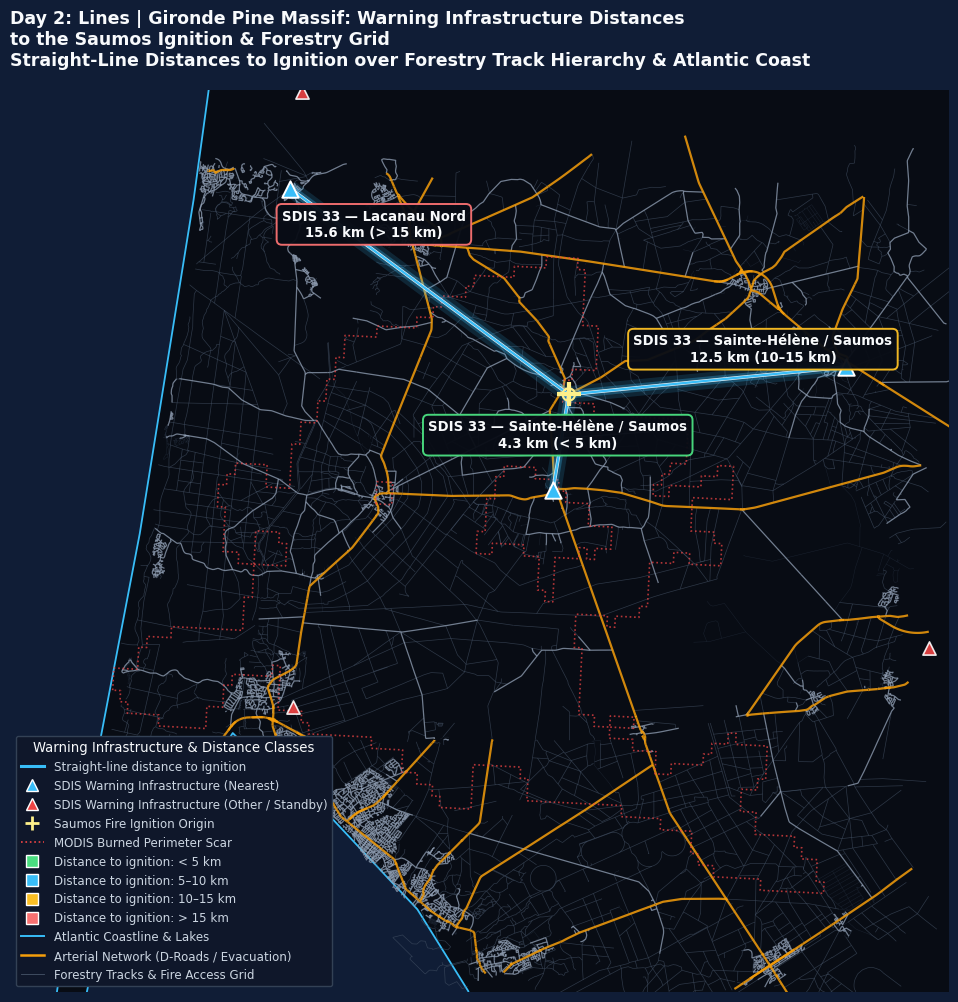

In [6]:
# Cell Nr: 006 - Master Render: Warning Infrastructure Distances & Forestry Grid

# Color palette: Lighter ocean vs. Dark forest mainland
ocean_color = "#101d36"
mainland_color = "#080c14"

fig, ax = plt.subplots(figsize=(10, 10), facecolor=ocean_color)
ax.set_facecolor(ocean_color)

# 1. Mainland France (clean boundary)
gdf_mainland_clean.plot(ax=ax, facecolor=mainland_color, edgecolor="#38bdf8", linewidth=1.3, zorder=1)

# 2. Coastal Lakes (Lac de Lacanau) in ocean tone
if gdf_lakes is not None and not gdf_lakes.empty:
    gdf_lakes.plot(ax=ax, facecolor=ocean_color, edgecolor="#38bdf8", linewidth=0.8, alpha=0.95, zorder=2)

# 3. Road & Forestry Track Hierarchy
road_styles = {
    "4. Service Pistes & Paths":        {"color": "#334155", "lw": 0.35, "alpha": 0.40, "zorder": 4},
    "3. Forest Tracks & Fire Access":  {"color": "#475569", "lw": 0.50, "alpha": 0.60, "zorder": 5},
    "2. Local / Connecting Roads":      {"color": "#94a3b8", "lw": 0.90, "alpha": 0.75, "zorder": 6},
    "1. Arterial / Regional (D-Roads)": {"color": "#f59e0b", "lw": 1.60, "alpha": 0.85, "zorder": 7},
}
for r_class, style in road_styles.items():
    if "road_class" in gdf_roads.columns:
        subset = gdf_roads[gdf_roads["road_class"] == r_class]
        if not subset.empty:
            subset.plot(ax=ax, color=style["color"], linewidth=style["lw"], alpha=style["alpha"], zorder=style["zorder"])

# 4. Burned Area Footprint Boundary
gdf_main_burn.boundary.plot(ax=ax, color="#ef4444", linewidth=1.2, linestyle=":", alpha=0.75, zorder=8)

# 5. Glowing Hero Sightlines (Multi-layer Laser Path Effects)
laser_glow = [
    pe.Stroke(linewidth=12.0, foreground="#38bdf8", alpha=0.15),
    pe.Stroke(linewidth=6.0,  foreground="#38bdf8", alpha=0.30),
    pe.Stroke(linewidth=2.5,  foreground="#ffffff", alpha=0.90),
    pe.Normal()
]
gdf_sightlines.plot(ax=ax, color="#38bdf8", linewidth=1.6, path_effects=laser_glow, zorder=9)

# 6. Quality Assessment Callout Badges along sightlines
for row in gdf_sightlines.itertuples():
    mid = row.geometry.interpolate(0.30, normalized=True)
    ax.annotate(
        f"{row.name}\n{row.dist_km:.1f} km ({row.quality_label})",
        xy=(mid.x, mid.y),
        xytext=(0, 10),
        textcoords="offset points",
        color="#f8fafc",
        fontsize=9.5,
        fontweight="bold",
        ha="center",
        bbox=dict(boxstyle="round,pad=0.40", facecolor="#090d16", edgecolor=row.quality_color, linewidth=1.4, alpha=0.96),
        zorder=14
    )

# 7. Ignition Target Crosshair & Tower Beacons
ax.scatter(target_pt.x, target_pt.y, marker="+", s=280, color="#fef08a", linewidth=3.0, zorder=12)
ax.scatter(target_pt.x, target_pt.y, marker="o", s=80, facecolor="none", edgecolor="#fef08a", linewidth=1.5, zorder=12)

# Closest 3 Warning Infrastructure Sites (Bright beacons)
closest_3.plot(ax=ax, color="#38bdf8", markersize=140, marker="^", edgecolor="#ffffff", linewidth=1.4, zorder=11)

# Other Warning / Surveillance Sites (Red markers)
if not other_towers.empty:
    other_towers.plot(ax=ax, color="#ef4444", markersize=90, marker="^", edgecolor="#ffffff", linewidth=1.2, alpha=0.90, zorder=10)

# Viewport Extents (Around active elements with 14% padding)
active_geoms = list(closest_3.geometry) + [target_pt] + [gdf_main_burn.geometry.iloc[0]]
bounds = gpd.GeoSeries(active_geoms).total_bounds
dx = (bounds[2] - bounds[0]) * 0.14
dy = (bounds[3] - bounds[1]) * 0.14
ax.set_xlim(bounds[0] - dx, bounds[2] + dx)
ax.set_ylim(bounds[1] - dy, bounds[3] + dy)
ax.set_axis_off()

# 8. Legend
legend_elements = [
    # Warning Infrastructure & Distances
    Line2D([0], [0], color="#38bdf8", lw=2.2, label="Straight-line distance to ignition"),
    Line2D([0], [0], marker="^", color="w", markerfacecolor="#38bdf8", markersize=9, lw=0, label="SDIS Warning Infrastructure (Nearest)"),
    Line2D([0], [0], marker="^", color="w", markerfacecolor="#ef4444", markeredgecolor="#ffffff", markersize=8, lw=0, label="SDIS Warning Infrastructure (Other / Standby)"),
    Line2D([0], [0], marker="+", color="#fef08a", markersize=10, mew=2, lw=0, label="Saumos Fire Ignition Origin"),
    Line2D([0], [0], color="#ef4444", lw=1.2, linestyle=":", label="MODIS Burned Perimeter Scar"),
    # Distance Categories
    Line2D([0], [0], marker="s", color="w", markerfacecolor="#4ade80", markersize=8, lw=0, label="Distance to ignition: < 5 km"),
    Line2D([0], [0], marker="s", color="w", markerfacecolor="#38bdf8", markersize=8, lw=0, label="Distance to ignition: 5–10 km"),
    Line2D([0], [0], marker="s", color="w", markerfacecolor="#fbbf24", markersize=8, lw=0, label="Distance to ignition: 10–15 km"),
    Line2D([0], [0], marker="s", color="w", markerfacecolor="#f87171", markersize=8, lw=0, label="Distance to ignition: > 15 km"),
    # Geography & Infrastructure
    Line2D([0], [0], color="#38bdf8", lw=1.4, label="Atlantic Coastline & Lakes"),
    Line2D([0], [0], color="#f59e0b", lw=1.8, label="Arterial Network (D-Roads / Evacuation)"),
    Line2D([0], [0], color="#475569", lw=0.6, label="Forestry Tracks & Fire Access Grid"),
]

legend = ax.legend(
    handles=legend_elements,
    title="Warning Infrastructure & Distance Classes",
    loc="lower left",        # <--- Solid background over open water
    framealpha=1.0,          # <--- 100% solid, fully opaque background
    facecolor="#0f172a",
    edgecolor="#334155",
    fontsize=8.5,
    title_fontsize=9.5
)
legend.get_title().set_color("#f8fafc")
for text in legend.get_texts():
    text.set_color("#cbd5e1")
legend.set_zorder(100)       # <--- Forces legend to the very top layer

# Master Title Block
ax.set_title(
    "Day 2: Lines | Gironde Pine Massif: Warning Infrastructure Distances \nto the Saumos Ignition & Forestry Grid\n"
    "Straight-Line Distances to Ignition over Forestry Track Hierarchy & Atlantic Coast",
    fontsize=12.5,
    fontweight="bold",
    color="#f8fafc",
    pad=18,
    loc="left"
)

plt.tight_layout()
fig.savefig("fire_lines_final.png", dpi=300, facecolor=ocean_color, bbox_inches="tight")
plt.show()
